# Lab 12-05 · Feedback: Theory and the Four Topologies

Companion to [chapter 12-05](../../chapters/12-05-feedback-topologies.md). Four parts: gain error against loop gain; the poles of a two-pole amplifier as the loop closes; return ratio, asymptotic and direct gains of Example 12-05.4's stage as $g_m$ varies; and second-harmonic distortion inside a loop. Run the cells in order.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

TP = 2 * math.pi


def solve(elems):
    """Linear DC circuit by nodal analysis. ('R', a, b, ohm); ('I', a, b, amps) leaves a, enters b;
    ('G', d, s, cp, cn, gm): gm*(v(cp) - v(cn)) leaves d, enters s."""
    nodes = sorted({n for e in elems for n in (e[1:3] if e[0] in 'RI' else e[1:5])} - {'0'})
    idx = {n: i for i, n in enumerate(nodes)}
    G, b = np.zeros((len(nodes),) * 2), np.zeros(len(nodes))
    def st(i, j, val):
        if i in idx and j in idx: G[idx[i], idx[j]] += val
    for e in elems:
        if e[0] == 'R':
            g = 1 / e[3]; st(e[1], e[1], g); st(e[2], e[2], g); st(e[1], e[2], -g); st(e[2], e[1], -g)
        elif e[0] == 'G':
            d, s, cp, cn, gm = e[1:]
            st(d, cp, gm); st(d, cn, -gm); st(s, cp, -gm); st(s, cn, gm)
        elif e[0] == 'I':
            if e[1] in idx: b[idx[e[1]]] -= e[3]
            if e[2] in idx: b[idx[e[2]]] += e[3]
    x = np.linalg.solve(G, b)
    out = {n: x[idx[n]] for n in nodes}; out['0'] = 0.0
    return out

## Part 1 · Gain error against loop gain

With β = 0.01, sweep the open-loop gain from 10 to 10⁶ and compare the closed-loop gain error with $1/(1 + T)$.

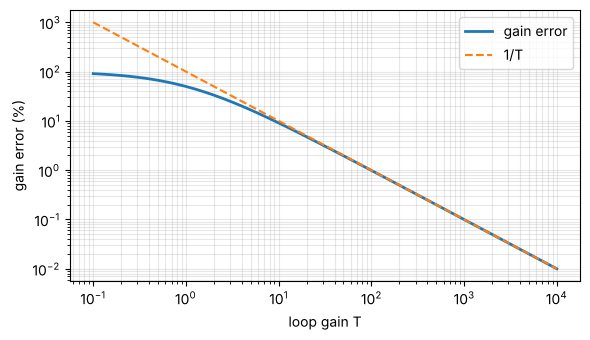

gain error at A = 1e3: 9.09%


In [2]:
beta = 0.01
A = np.logspace(1, 6, 51)
Af = A / (1 + A * beta)
err = 1 - Af * beta
T = A * beta
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.loglog(T, 100 * err, lw=2, label='gain error')
ax.loglog(T, 100 / T, '--', label='1/T')
ax.set_xlabel('loop gain T'); ax.set_ylabel('gain error (%)'); ax.grid(True, which='both', alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()
print(f"gain error at A = 1e3: {100 * (1 - 1e3 / (1 + 1e3 * beta) * beta):.2f}%")

## Part 2 · Closing the loop around two poles

$A(s) = A_0/[(1 + s/\omega_1)(1 + s/\omega_2)]$ with $A_0$ = 10⁴, $f_1$ = 1 kHz and $f_2$ = 1 MHz. The closed-loop poles are the roots of $(1 + s/\omega_1)(1 + s/\omega_2) + A_0\beta = 0$. As β grows the two real poles move toward each other, meet, and split into a complex pair: the beginning of the stability question in 12-06.

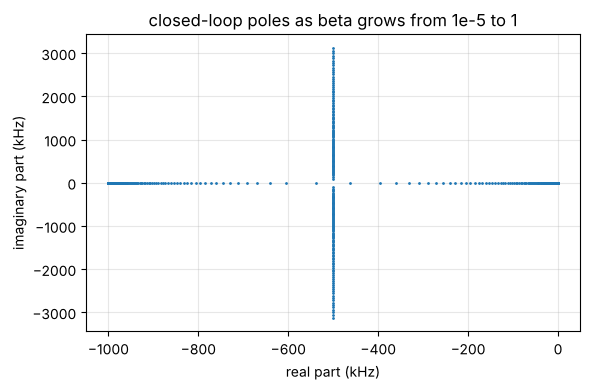

poles meet at beta = 0.02495, at 500.5 kHz
beta = 0.1: poles -500.5+866.3j kHz, Q = 0.9995


In [3]:
A0, f1, f2 = 1e4, 1e3, 1e6
w1, w2 = TP * f1, TP * f2
def cl_poles(b):
    return np.roots([1 / (w1 * w2), 1 / w1 + 1 / w2, 1 + A0 * b])
betas = np.logspace(-5, 0, 300)
P = np.array([cl_poles(b) for b in betas])
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(P.real.ravel() / TP / 1e3, P.imag.ravel() / TP / 1e3, '.', ms=2)
ax.set_xlabel('real part (kHz)'); ax.set_ylabel('imaginary part (kHz)'); ax.grid(True, alpha=0.3)
ax.set_title('closed-loop poles as beta grows from 1e-5 to 1')
plt.tight_layout(); plt.show()
bm = brentq(lambda b: (1 / w1 + 1 / w2) ** 2 - 4 * (1 + A0 * b) / (w1 * w2), 1e-6, 1.0, xtol=1e-15)
print(f"poles meet at beta = {bm:.5f}, at {abs(cl_poles(bm)[0].real) / TP / 1e3:.1f} kHz")
p = cl_poles(0.1); wn = math.sqrt(abs(p[0] * p[1]))
print(f"beta = 0.1: poles {p[0] / TP / 1e3:.1f} kHz, Q = {wn / abs(p[0].real + p[1].real):.4f}")

## Part 3 · Return ratio, asymptotic gain and direct transmission

Example 12-05.4's shunt–shunt stage: $R_D$ = 10 kΩ, $R_F$ = 50 kΩ, $R_S$ = 10 kΩ. For each $g_m$, the controlled source is replaced by an independent current to find $T$, and the input is applied with the source zeroed and with $g_m \to \infty$ to find $A_0$ and $A_\infty$. The asymptotic-gain formula is then compared with the direct solution.

In [4]:
RD, RF, RS = 10e3, 50e3, 10e3
def stage(gm, u, sc=None):
    el = [('R', 'g', '0', RS), ('R', 'g', 'd', RF), ('R', 'd', '0', RD), ('I', '0', 'g', u)]
    el.append(('G', 'd', '0', 'g', '0', gm) if sc is None else ('I', 'd', '0', sc))
    return el
rows = []
for gm in [0.5e-3, 1e-3, 2e-3, 4e-3, 8e-3, 16e-3]:
    s1 = solve(stage(gm, 1.0, 0.0)); s2 = solve(stage(gm, 0.0, 1.0))
    a, c = s1['d'], s1['g']; b, d = s2['d'], s2['g']
    T = -gm * d; A0_, Ainf = a, a - b * c / d
    Af = solve(stage(gm, 1.0))['d']
    rows.append((gm, T, Ainf, A0_, (Ainf * T + A0_) / (1 + T), Af))
print(' gm (mA/V)     T     A_inf (kΩ)  A_dir (kΩ) formula (kΩ)  direct (kΩ)')
for gm, T, Ai, A0_, fo, di in rows:
    print(f"{gm * 1e3:8.1f} {T:8.3f} {Ai / 1e3:10.2f} {A0_ / 1e3:9.4f} {fo / 1e3:12.4f} {di / 1e3:12.4f}")

 gm (mA/V)     T     A_inf (kΩ)  A_dir (kΩ) formula (kΩ)  direct (kΩ)
     0.5    0.714     -50.00    1.4286     -20.0000     -20.0000
     1.0    1.429     -50.00    1.4286     -28.8235     -28.8235
     2.0    2.857     -50.00    1.4286     -36.6667     -36.6667
     4.0    5.714     -50.00    1.4286     -42.3404     -42.3404
     8.0   11.429     -50.00    1.4286     -45.8621     -45.8621
    16.0   22.857     -50.00    1.4286     -47.8443     -47.8443


## Part 4 · Distortion inside the loop (the chapter's guided exercise)

The amplifier is $y = a_1(e + c\,e^2)$ with $a_1$ = 1000 and $c$ = 5 V⁻¹: at 1 V output its error input is about 1 mV and its second harmonic is $cE/2$ = 0.25%. **Predict first:** placed in a loop with β = 0.099 ($T$ = 99), at the same 1 V output, how much does the second harmonic fall? The loop is solved exactly at each sample (the quadratic for $e$), and the harmonics come from an FFT.

In [5]:
a1, c, beta = 1000.0, 5.0, 0.099
N = 4096; cs = np.cos(TP * np.arange(N) / N)
def harm(y):
    F = np.fft.rfft(y) / N * 2
    return abs(F[1]), abs(F[2])
def open_loop(E):
    e = E * cs; return a1 * (e + c * e * e)
def closed_loop(X):
    Aq, Bq = beta * a1 * c, 1 + beta * a1
    e = (-Bq + np.sqrt(Bq * Bq + 4 * Aq * X * cs)) / (2 * Aq)
    return a1 * (e + c * e * e)
Eo = brentq(lambda E: harm(open_loop(E))[0] - 1.0, 1e-9, 1.0, xtol=1e-18)
Xc = brentq(lambda X: harm(closed_loop(X))[0] - 1.0, 1e-9, 0.9 * (1 + beta * a1) ** 2 / (4 * beta * a1 * c), xtol=1e-16)
h_ol = harm(open_loop(Eo)); h_cl = harm(closed_loop(Xc))
print(f"open loop:   HD2 = {100 * h_ol[1] / h_ol[0]:.4f}%")
print(f"closed loop: HD2 = {100 * h_cl[1] / h_cl[0]:.5f}%  (input amplitude {Xc:.4f} V)")
print(f"reduction = {(h_ol[1] / h_ol[0]) / (h_cl[1] / h_cl[0]):.2f}, against 1 + T = {1 + a1 * beta:.0f}")

open loop:   HD2 = 0.2500%
closed loop: HD2 = 0.00250%  (input amplitude 0.1000 V)
reduction = 99.99, against 1 + T = 100


**Discussion.** The reduction is $1 + T$ to within a hundredth of a percent: the amplifier still works on about 1 mV of error signal, but the loop subtracts most of the harmonic it creates. Try $c$ ten times larger: the reduction stays close to $1 + T$ as long as the amplifier's incremental gain varies little over the cycle.